# 01 · Instrument nodes

Block 1 check: run each instrument node alone on a hand-made state — preflight, status, move, set FOV, overview, EDS — plus one forced error.

**Before running (twin):** `uv run python scripts/twin.py start` in a terminal.

**Real microscope:** `INSTRUMENT = "real"`, real stage coordinates in `SETTINGS`, `STEM_REAL_MCP_URL` in `.env`.

Each node returns only what it changed; `apply` merges it into a **new** state dict, so a saved `before` state stays as it was (needed for undo).

In [2]:
INSTRUMENT = "real"   # "twin" or "real"

SETTINGS = {
    "instrument": INSTRUMENT,
    "stage_xy_m": (5e-9, 0.0),     # move node: stage x, y (twin repeats every FOV: avoid multiples of it)
    "tuning_fov_m": 40e-9,          # set_fov node (the twin fails at 50 / 100 / 200 nm)
    "run_tag": "block1",
}

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image
from scipy import ndimage as ndi
from skimage.filters import threshold_otsu

from stem_agent.config import INSTRUMENTS
from stem_agent.data import tiled_io
from stem_agent.mcp import session
from stem_agent.nodes import common
from stem_agent.nodes.eds_node import eds_node
from stem_agent.nodes.move_stage_node import move_stage_node, undo_move
from stem_agent.nodes.overview_node import overview_node
from stem_agent.nodes.preflight_node import preflight_node
from stem_agent.nodes.set_fov_node import set_fov_node, undo_fov
from stem_agent.nodes.status_node import status_node


def apply(state, update):
    """Merge a node's update into a new state dict."""
    print("->", sorted(update), "| run_status:", update.get("run_status", state.get("run_status")))
    if "error" in update:
        print("ERROR:", update["error"])
    return {**state, **update}


def show(images, titles, points=None):
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 5), squeeze=False)
    for ax, image, title in zip(axes[0], images, titles):
        ax.imshow(image, cmap="gray")
        for i, (row, col) in enumerate(points or [], start=1):
            ax.plot(col, row, "o", mfc="none", mec="tab:red", ms=14, mew=2)
            ax.text(col + 10, row - 10, str(i), color="tab:red", weight="bold")
        ax.set_title(title)
        ax.axis("off")
    plt.show()


state = {"settings": SETTINGS}
state

{'settings': {'target': 'real',
  'target_xy_m': (5e-09, 0.0),
  'tuning_fov_m': 4e-08,
  'run_tag': 'block1'}}

## 1 · Preflight
Connects, checks all 14 tools, creates the run folder. Expected: `run_status: running`.

In [4]:
state = apply(state, await preflight_node(state))
state["run"]["run_dir"]

[preflight] FAILED: unhandled errors in a TaskGroup (1 sub-exception)
-> ['errors', 'run', 'run_status'] | run_status: failed


'/Users/borisslautin/Documents/GitHub/STEM_Particle_Analysis/runs/20261105_081916_block1'

## 2 · Status: first snapshot (the readiness gate)
Expected on the twin: `ready: True`, all devices `ON`, warnings only for fields the twin does not report.

In [5]:
state = apply(state, await status_node(state))
snap = state["snapshots"][0]
{key: snap[key] for key in ("stage", "fov_m", "stem_mode", "devices", "ready", "problems", "warnings")}

[status_start] stage [+0, +0, +0, +0, +0] | FOV 1.999999987845058e-08 m | devices 6 (all ON) | ready True
[status_start] warning: beam_blanked unknown
[status_start] warning: column_valves_open unknown
[status_start] warning: high_tension_on unknown
[status_start] warning: beam_stopper_out unknown
-> ['current', 'start'] | run_status: running


{'stage': [0.0, 0.0, 0.0, 0.0, 0.0],
 'fov_m': 1.999999987845058e-08,
 'stem_mode': True,
 'devices': {'DATA': 'ON',
  'DigitalTwinCorrector': 'ON',
  'DigitalTwinParticles': 'ON',
  'EDS': 'ON',
  'SCAN': 'ON',
  'TestStage': 'ON'},
 'ready': True,
 'problems': [],
 'warnings': ['beam_blanked unknown',
  'column_valves_open unknown',
  'high_tension_on unknown',
  'beam_stopper_out unknown']}

## 3 · Move
Move to `stage_xy_m`, image before and after, then undo. Expected: readback within 10 nm, image shifted, back at the start.

[move] (+0.0000, +0.0000) -> (+0.0050, +0.0000) um
-> ['current'] | run_status: running


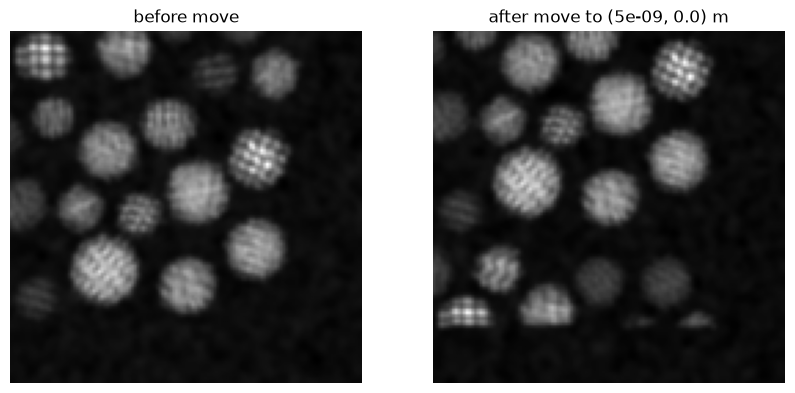

-> ['current'] | run_status: running
stage after undo: [0.0, 0.0, 0.0, 0.0, 0.0]


In [6]:
_, image_before = await common.acquire_haadf()
before = state
state = apply(state, await move_stage_node(state))
_, image_after = await common.acquire_haadf()
show([image_before, image_after], ["before move", f"after move to {SETTINGS['stage_xy_m']} m"])

await undo_move(before)
state = apply(state, {"current": {**state["current"], "stage": await common.get_stage()}})
print("stage after undo:", state["current"]["stage"])

## 4 · Set FOV
Zoom to `tuning_fov_m`, image, then undo. Expected: readback within 1 %, wider view, back to the start FOV.

The twin rebuilds its sample when the FOV changes, so the scene may differ between the two images.

[set_fov] 20.0 -> 40.0 nm
-> ['current'] | run_status: running
-> ['current'] | run_status: running


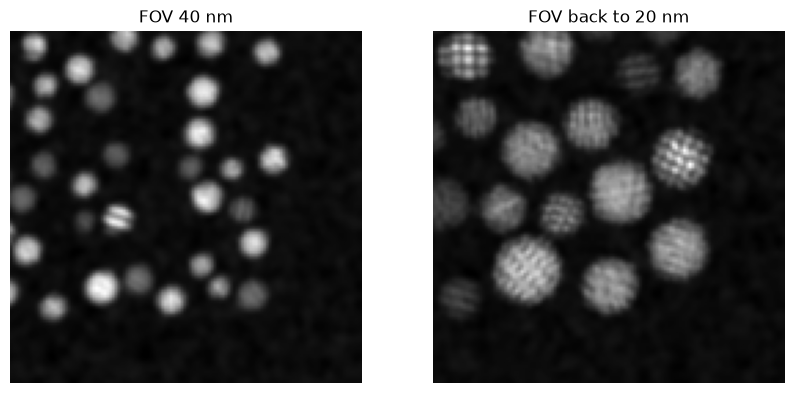

In [7]:
before = state
state = apply(state, await set_fov_node(state))
_, image_zoom = await common.acquire_haadf()

await undo_fov(before)
state = apply(state, {"current": {**state["current"], "fov_m": await session.call("get_fov")}})
_, image_back = await common.acquire_haadf()
show([image_zoom, image_back],
     [f"FOV {SETTINGS['tuning_fov_m'] * 1e9:.0f} nm", f"FOV back to {state['current']['fov_m'] * 1e9:.0f} nm"])

## 5 · Overview
Expected: Tiled key, image shape, `overview.png` in the run folder.

In [8]:
state = apply(state, await overview_node(state))
image = tiled_io.read_image(state["overview"]["tiled_key"])
state["overview"]

[overview] stem_image_HAADF_20261103T200255302516.h5 (128, 128) -> overview.png
-> ['overview'] | run_status: running


{'tiled_key': 'stem_image_HAADF_20261103T200255302516.h5',
 'fov_m': 1.999999987845058e-08,
 'shape': [128, 128],
 'preview_path': '/Users/borisslautin/Documents/GitHub/STEM_Particle_Analysis/runs/20261103_200158_block1/overview.png'}

## 6 · EDS and beam order
Test-only point picking (real segmentation comes in block 3): the 3 widest bright particles (deepest interior pixel) and the darkest background point.

Then the EDS node runs with **both** beam orders (twin: `scripts/twin.py` sets the scan to 128 px, the size of the twin's particle map, otherwise its EDS misses the particles). On the twin a particle gives its composition (max fraction ≳ 0.3) and background gives noise (≲ 0.15). The order where the 3 bright points hit and the dark point misses is the right one for this instrument.

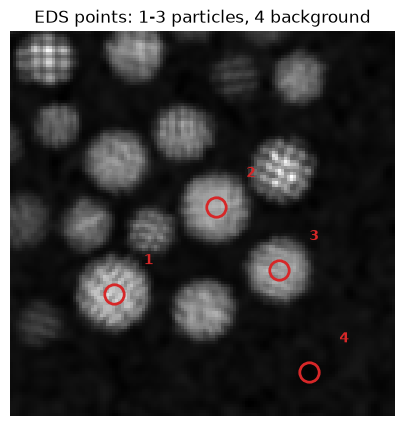

[{'id': 1, 'row': 87.0, 'col': 34.0},
 {'id': 2, 'row': 58.0, 'col': 68.0},
 {'id': 3, 'row': 79.0, 'col': 89.0},
 {'id': 4, 'row': 113.0, 'col': 99.0}]

In [9]:
smooth = ndi.gaussian_filter(image, 1.5 * image.shape[0] / 128)   # same blur at 128 or 512 px
mask = smooth > threshold_otsu(smooth)
labels, n = ndi.label(mask)
depth = ndi.distance_transform_edt(mask)
widest = np.argsort(ndi.maximum(depth, labels, range(1, n + 1)))[::-1][:3] + 1
bright = [ndi.maximum_position(depth, labels, label) for label in widest]
dark = np.unravel_index(np.argmin(smooth), smooth.shape)

points = bright + [dark]
particles = [{"id": i, "row": float(r), "col": float(c)} for i, (r, c) in enumerate(points, start=1)]
show([image], ["EDS points: 1-3 particles, 4 background"], points)
particles

In [10]:
HIT = 0.25   # twin: max element fraction on a particle vs background noise

score = {}
for order in ("col_row", "row_col"):
    trial = {**state, "particles": particles, "settings": {**SETTINGS, "beam_order": order}}
    update = await eds_node(trial)
    if "error" in update:
        print(order, "ERROR:", update["error"])
        continue
    hits = [bool(np.load(r["npy_path"]).max() > HIT) for r in update["spectra"]]
    score[order] = sum(hits[:3]) + (not hits[3])
    print(f"{order}: particles {['hit' if h else 'miss' for h in hits[:3]]}, "
          f"background {'hit' if hits[3] else 'miss'} -> score {score[order]}/4\n")

best = max(score, key=score.get)
print(f"best beam order for {INSTRUMENT}: {best!r}; config has {INSTRUMENTS[INSTRUMENT]['beam_order']!r}")

[eds] particle 1 at beam (0.266, 0.680): 3 values, max 0.0751
[eds] particle 2 at beam (0.531, 0.453): 3 values, max 0.0892
[eds] particle 3 at beam (0.695, 0.617): 3 values, max 0.0206
[eds] particle 4 at beam (0.773, 0.883): 3 values, max 0.0425
col_row: particles ['miss', 'miss', 'miss'], background miss -> score 1/4

[eds] particle 1 at beam (0.680, 0.266): 1 values, max 1.11
[eds] particle 2 at beam (0.453, 0.531): 1 values, max 1.02
[eds] particle 3 at beam (0.617, 0.695): 1 values, max 0.953
[eds] particle 4 at beam (0.883, 0.773): 3 values, max 0.0769
row_col: particles ['hit', 'hit', 'hit'], background miss -> score 4/4

best beam order for twin: 'row_col'; config has 'row_col'


EDS with the configured order (no override), stored in the state:

[eds] particle 1 at beam (0.680, 0.266): 1 values, max 0.987
[eds] particle 2 at beam (0.453, 0.531): 1 values, max 1.01
[eds] particle 3 at beam (0.617, 0.695): 1 values, max 0.968
[eds] particle 4 at beam (0.883, 0.773): 3 values, max 0.0404
-> ['spectra'] | run_status: running


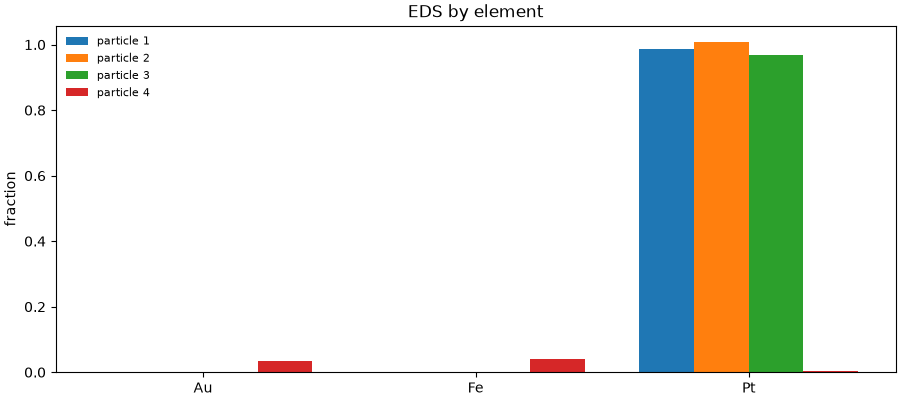

In [11]:
state = apply({**state, "particles": particles}, await eds_node({**state, "particles": particles}))
Image(Path(state["run"]["run_dir"]) / "eds.png")

## 7 · Forced error
A 1 mm move is over the 100 µm limit. Expected: `run_status: failed`, an error message, the stage unchanged.

In [12]:
stage_before = await common.get_stage()
bad = {**state, "settings": {**SETTINGS, "stage_xy_m": (1e-3, 0.0)}}
update = await move_stage_node(bad)
print(update)
print("stage unchanged:", await common.get_stage() == stage_before)

[move_stage] FAILED: x/y move of 1000.000 um exceeds 100 um
[move_stage] undo done
{'run_status': 'failed', 'error': 'move_stage: ValueError: x/y move of 1000.000 um exceeds 100 um'}
stage unchanged: True


## 8 · Status: final snapshot
Final snapshot, then the files this run produced.

In [13]:
state = apply(state, await status_node(state))
run_dir = Path(state["run"]["run_dir"])
sorted(str(p.relative_to(run_dir)) for p in run_dir.rglob("*") if p.is_file())

[status_end] stage [+0, +0, +0, +0, +0] | FOV 1.999999987845058e-08 m | devices 6 (all ON) | ready True
[status_end] warning: beam_blanked unknown
[status_end] warning: column_valves_open unknown
[status_end] warning: high_tension_on unknown
[status_end] warning: beam_stopper_out unknown
-> ['end'] | run_status: running


['eds.png',
 'overview.png',
 'settings.json',
 'spectra/particle_001.npy',
 'spectra/particle_002.npy',
 'spectra/particle_003.npy',
 'spectra/particle_004.npy',
 'status_end.json',
 'status_start.json']